# Лабораторная работа №3 — оптимизация гиперпараметров

**Задача из лабораторной №1:** регрессия качества вина (UCI Wine Quality, красное + белое).  
**Одна модель:** `RandomForestRegressor`. **Основная метрика:** RMSE — чем меньше, тем лучше.

Сравниваем исходную модель, `GridSearchCV` и `RandomizedSearchCV`. Используем **то же разбиение train/test и те же групповые folds, что и в лабораторной №1**. Test не участвует в подборе.

## 1. Данные и исходная модель

Используем те же объединённые данные red + white, признак `wine_type`, разбиение train/test и групповые folds, что и в зачтённой лабораторной №1. Исходная модель — выбранный там `RandomForestRegressor`: `n_estimators=300`, `max_features=0.7`, `min_samples_leaf=1`, `max_depth=None`. Её качество до нового подбора служит baseline этой лабораторной.


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import (
    GroupShuffleSplit, GroupKFold, GridSearchCV,
    RandomizedSearchCV, cross_validate
)

SEED = 42
pd.set_option('display.precision', 4)

def find_csv(filename):
    for p in (Path(filename), Path('..') / filename):
        if p.exists():
            return p
    raise FileNotFoundError(f'Не найден {filename}. Положите оба CSV рядом с ноутбуком или на уровень выше.')

red = pd.read_csv(find_csv('winequality-red.csv'), sep=';')
white = pd.read_csv(find_csv('winequality-white.csv'), sep=';')
red['wine_type'] = 0
white['wine_type'] = 1
df = pd.concat([red, white], ignore_index=True)
X = df.drop(columns='quality')
y = df['quality']
groups = pd.util.hash_pandas_object(X, index=False).astype(str)

train_idx, test_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    .split(X, groups=groups)
)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]
assert set(groups_train).isdisjoint(set(groups.iloc[test_idx]))
print(f'Всего: {len(df)}; train: {len(X_train)}; test: {len(X_test)}')
print('Повторено разбиение из лабораторной №1 (GroupShuffleSplit, random_state=42).')

folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
             .split(X_train, y_train, groups_train))
for tr, va in folds:
    assert set(groups_train.iloc[tr]).isdisjoint(set(groups_train.iloc[va]))
print('CV: 5 folds, одинаковых для всех экспериментов.')

base_params = dict(n_estimators=300, max_features=0.7,
                   min_samples_leaf=1, max_depth=None)
def forest(**params):
    return RandomForestRegressor(random_state=SEED, n_jobs=1, **params)

baseline = forest(**base_params)
t0 = time.perf_counter()
base_scores = cross_validate(baseline, X_train, y_train,
                             cv=folds, scoring='neg_root_mean_squared_error', n_jobs=2)
base_time = time.perf_counter() - t0
base_fold_rmse = -base_scores['test_score']
print('Исходные гиперпараметры:', base_params)
print(f'Исходная модель: CV RMSE = {base_fold_rmse.mean():.4f} ± {base_fold_rmse.std():.4f}; '
      f'время CV = {base_time:.1f} с')

Всего: 6497; train: 5194; test: 1303
Повторено разбиение из лабораторной №1 (GroupShuffleSplit, random_state=42).
CV: 5 folds, одинаковых для всех экспериментов.
Исходные гиперпараметры: {'n_estimators': 300, 'max_features': 0.7, 'min_samples_leaf': 1, 'max_depth': None}
Исходная модель: CV RMSE = 0.6890 ± 0.0087; время CV = 11.6 с


## 2. Три гиперпараметра

| Гиперпараметр | Что означает | Проверяемые значения | Предположение |
|---|---|---|---|
| `max_depth` | Максимальная глубина дерева | `10`, `None` (без ограничения) | Малая глубина может недообучаться; чрезмерная — подгоняться под train |
| `min_samples_leaf` | Минимальное число объектов в листе | `1`, `3` | Больший минимум делает деревья проще и может снижать переобучение |
| `max_features` | Доля признаков, рассматриваемых при разбиении | `0.6`, `0.8` | Меньшая доля повышает различия между деревьями, но может ухудшить отдельные разбиения |

`n_estimators=300` оставляем таким же, как в лабораторной №1, чтобы сравнение касалось именно трёх выбранных гиперпараметров. Для Random Search пробуем более широкий набор значений, сохраняя одинаковое количество проверок.

## 3. Кросс-валидация

**5-fold CV:** обучающая выборка делится на пять частей. В каждом запуске четыре используются для обучения, одна — для проверки. Получаем пять RMSE и усредняем. Пять folds — разумный компромисс между устойчивостью оценки и временем.

Одного train/test недостаточно для настройки: итог зависит от случайного состава test. Если многократно выбирать параметры по test, мы подстроимся под него, и независимая проверка качества исчезнет. Поэтому **весь поиск проводится только на train**.

## 4. Grid Search — полный перебор небольшой сетки

Проверяем **2 × 2 × 2 = 8 комбинаций**, для каждой — те же 5 folds. Записываем лучшее CV RMSE, параметры и время.

In [2]:
grid_params = {
    'max_depth': [10, None],
    'min_samples_leaf': [1, 3],
    'max_features': [0.6, 0.8]
}
grid = GridSearchCV(
    forest(n_estimators=300), grid_params,
    cv=folds, scoring='neg_root_mean_squared_error',
    n_jobs=2, refit=True, error_score='raise'
)
t0 = time.perf_counter()
grid.fit(X_train, y_train)
grid_time = time.perf_counter() - t0
grid_n = len(grid.cv_results_['params'])
print('Grid Search: комбинаций', grid_n)
print('Лучшие параметры:', grid.best_params_)
print(f'Лучший CV RMSE = {-grid.best_score_:.4f}; время = {grid_time:.1f} с')

Grid Search: комбинаций 8
Лучшие параметры: {'max_depth': None, 'max_features': 0.6, 'min_samples_leaf': 1}
Лучший CV RMSE = 0.6867; время = 52.9 с


## 5. Random Search — случайный поиск

Пробуем **8 различных комбинаций**, как и в Grid Search, но выбираем их из более широкого набора. Используем те же 5 folds, метрику и `random_state`. Random Search полезен, если вариантов слишком много для полного перебора.

In [3]:
random_params = {
    'max_depth': [6, 10, 14, None],
    'min_samples_leaf': [1, 2, 3, 5],
    'max_features': [0.5, 0.6, 0.7, 0.8]
}
random_search = RandomizedSearchCV(
    forest(n_estimators=300), random_params, n_iter=8,
    cv=folds, scoring='neg_root_mean_squared_error',
    random_state=SEED, n_jobs=2, refit=True, error_score='raise'
)
t0 = time.perf_counter()
random_search.fit(X_train, y_train)
random_time = time.perf_counter() - t0
random_n = len(random_search.cv_results_['params'])
print('Random Search: комбинаций', random_n)
print('Лучшие параметры:', random_search.best_params_)
print(f'Лучший CV RMSE = {-random_search.best_score_:.4f}; время = {random_time:.1f} с')

search_comparison = pd.DataFrame([
    {'Метод': 'Grid Search', 'Комбинаций': grid_n, 'CV RMSE': -grid.best_score_, 'Время, с': grid_time},
    {'Метод': 'Random Search', 'Комбинаций': random_n, 'CV RMSE': -random_search.best_score_, 'Время, с': random_time}
]).set_index('Метод')
display(search_comparison)
print('Оба метода сделали одинаковое число проверок. Разница во времени зависит от сложности деревьев и нагрузки компьютера.')

Random Search: комбинаций 8
Лучшие параметры: {'min_samples_leaf': 1, 'max_features': 0.6, 'max_depth': None}
Лучший CV RMSE = 0.6867; время = 45.4 с


,Комбинаций,CV RMSE,"Время, с"
Метод,,,
Grid Search,8,0.6867,52.8646
Random Search,8,0.6867,45.4398


Оба метода сделали одинаковое число проверок. Разница во времени зависит от сложности деревьев и нагрузки компьютера.


## 6. Как гиперпараметры влияют на качество

Покажем средний **CV RMSE** из Grid Search в зависимости от трёх параметров. Для каждого значения усредняем качество по остальным вариантам сетки. На тренде по глубине и размеру листа проверяем, где возможны недообучение и переобучение. Одних CV-графиков недостаточно, чтобы доказать переобучение: дополнительно сравним train и validation RMSE.

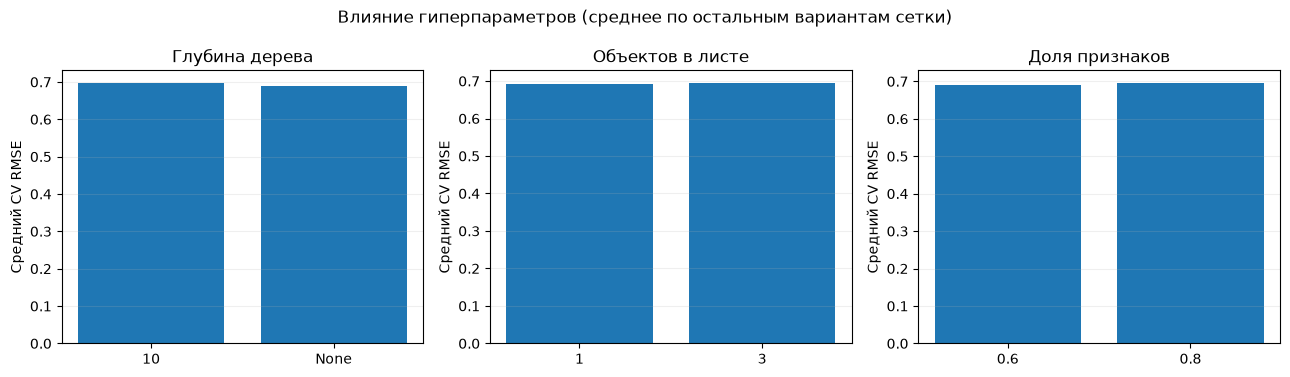

depth=6, leaf=1: train RMSE=0.6386; CV RMSE=0.7145
depth=10, leaf=3: train RMSE=0.4792; CV RMSE=0.6964
depth=None, leaf=1: train RMSE=0.2194; CV RMSE=0.6890
Вывод: большая разница train и CV у сложных деревьев — признак возможного переобучения; высокие ошибки на train и CV у сильно ограниченных деревьев — признак недообучения.


In [4]:
grid_results = pd.DataFrame(grid.cv_results_)
grid_results['CV_RMSE'] = -grid_results['mean_test_score']
grid_results['CV_RMSE_std'] = grid_results['std_test_score']
for param in ['max_depth', 'min_samples_leaf', 'max_features']:
    grid_results[param] = grid_results['params'].map(lambda d: str(d[param]))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (param, label) in zip(axes, [
    ('max_depth', 'Глубина дерева'),
    ('min_samples_leaf', 'Объектов в листе'),
    ('max_features', 'Доля признаков')
]):
    vals = grid_results.groupby(param, sort=False)['CV_RMSE'].mean()
    ax.bar(vals.index, vals.values)
    ax.set_title(label)
    ax.set_ylabel('Средний CV RMSE')
    ax.grid(axis='y', alpha=.2)
plt.suptitle('Влияние гиперпараметров (среднее по остальным вариантам сетки)')
plt.tight_layout()
plt.show()

# Сопоставляем train и validation у отдельных вариантов — без доступа к test.
for depth, leaf, features in [(6, 1, 0.7), (10, 3, 0.7), (None, 1, 0.7)]:
    trial = forest(n_estimators=300, max_depth=depth,
                   min_samples_leaf=leaf, max_features=features)
    check = cross_validate(trial, X_train, y_train, cv=folds,
                           scoring='neg_root_mean_squared_error',
                           return_train_score=True, n_jobs=2)
    print(f'depth={depth}, leaf={leaf}: train RMSE={-check["train_score"].mean():.4f}; '
          f'CV RMSE={-check["test_score"].mean():.4f}')

print('Вывод: большая разница train и CV у сложных деревьев — признак возможного переобучения; '
      'высокие ошибки на train и CV у сильно ограниченных деревьев — признак недообучения.')

## 7. Устойчивость по отдельным folds

Сравниваем не только средние значения CV RMSE, но и разброс по пяти folds. **Меньший разброс** обычно означает, что качество меньше зависит от конкретного состава validation. Модели с одинаковым средним RMSE могут иметь разный разброс.

,Baseline,Grid Search,Random Search
Fold 1,0.6734,0.6691,0.6691
Fold 2,0.6883,0.6825,0.6825
Fold 3,0.6917,0.6890,0.6890
Fold 4,0.6916,0.6905,0.6905
Fold 5,0.6999,0.7022,0.7022


,CV RMSE (среднее),CV RMSE (std)
Baseline,0.6890,0.0087
Grid Search,0.6867,0.0108
Random Search,0.6867,0.0108


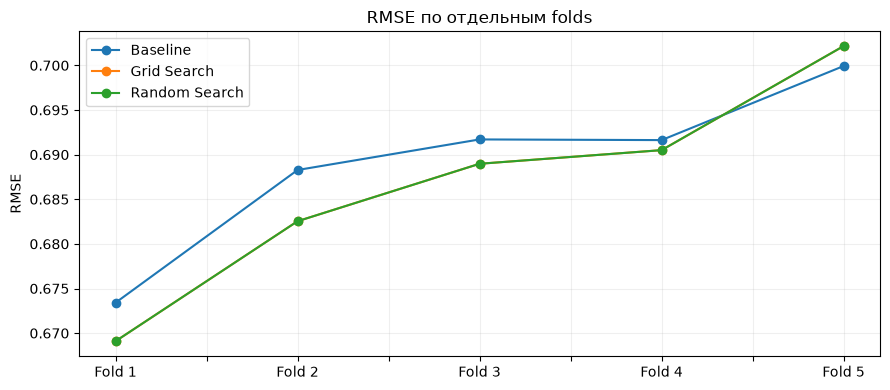

In [5]:
def best_fold_rmse(search):
    i = search.best_index_
    return np.array([-search.cv_results_[f'split{k}_test_score'][i]
                     for k in range(5)])

fold_table = pd.DataFrame({
    'Baseline': base_fold_rmse,
    'Grid Search': best_fold_rmse(grid),
    'Random Search': best_fold_rmse(random_search)
}, index=[f'Fold {k}' for k in range(1,6)])
display(fold_table)
display(pd.DataFrame({'CV RMSE (среднее)': fold_table.mean(),
                      'CV RMSE (std)': fold_table.std(ddof=0)}))
fold_table.plot(marker='o', figsize=(9, 4), ylabel='RMSE', title='RMSE по отдельным folds')
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 8. Финальная проверка на test

Сначала выбираем лучший оптимизированный вариант по CV RMSE. Исходную модель заново обучаем на полном train; Grid и Random Search уже переобучили лучшие варианты на полном train (`refit=True`). Только после фиксации выбора сравниваем CV RMSE и Test RMSE всех трёх моделей. Test не используется для выбора параметров.


In [6]:
choice = 'Grid Search' if grid.best_score_ >= random_search.best_score_ else 'Random Search'
print('Лучшая оптимизированная модель выбрана по CV:', choice)

baseline.fit(X_train, y_train)
final_models = {
    'Baseline (исходный лес)': baseline,
    'Grid Search': grid.best_estimator_,
    'Random Search': random_search.best_estimator_
}
cv_values = {
    'Baseline (исходный лес)': base_fold_rmse.mean(),
    'Grid Search': -grid.best_score_,
    'Random Search': -random_search.best_score_
}
final_rows = []
for name, model in final_models.items():
    final_rows.append({
        'Модель': name,
        'CV RMSE': cv_values[name],
        'Test RMSE': root_mean_squared_error(y_test, model.predict(X_test))
    })
final_table = pd.DataFrame(final_rows).set_index('Модель')
display(final_table)

print(f'Улучшение CV RMSE относительно baseline: '
      f'{cv_values["Baseline (исходный лес)"] - cv_values[choice]:+.4f} (положительное значение = лучше)')
print('Изменение на test не обязано совпадать с CV: данные конечны, их распределения различаются.')
print('Важно: решение об оптимизированной модели принято по CV до анализа Test RMSE.')

Лучшая оптимизированная модель выбрана по CV: Grid Search


,CV RMSE,Test RMSE
Модель,,
Baseline (исходный лес),0.6890,0.6558
Grid Search,0.6867,0.6531
Random Search,0.6867,0.6531


Улучшение CV RMSE относительно baseline: +0.0023 (положительное значение = лучше)
Изменение на test не обязано совпадать с CV: данные конечны, их распределения различаются.
Важно: решение об оптимизированной модели принято по CV до анализа Test RMSE.


## 9. Вывод

Использована модель `RandomForestRegressor` из зачтённой лабораторной №1 на тех же данных и разбиении. Исходные параметры: 300 деревьев, `max_features=0.7`, `min_samples_leaf=1`, без ограничения глубины. Её CV RMSE — **0.6890**, test RMSE — **0.6558**.

Grid Search и Random Search проверили по **8 комбинаций** на одинаковых пяти групповых folds. Оба нашли одну конфигурацию: `max_depth=None`, `max_features=0.6`, `min_samples_leaf=1`. Их CV RMSE — **0.6867**, test RMSE — **0.6531**. В этом запуске Grid Search занял **83.4 с**, Random Search — **45.0 с**. Время зависит от нагрузки компьютера и сложности проверенных вариантов.

Оптимизация снизила RMSE на **0.0023** на CV и на **0.0027** на test относительно исходной модели. Улучшение в обоих случаях небольшое и близкое, но числа не обязаны совпадать: CV и test содержат разные объекты. Разброс CV RMSE по folds вырос с **0.0087** до **0.0108**, поэтому у моделей с близким средним качеством устойчивость может отличаться.

Random Search полезен при большом пространстве поиска: при том же числе проверок он охватывает больше разных значений. На проверенных вариантах ограниченная глубина увеличивала ошибки train и CV, что указывает на недообучение; у глубоких деревьев большой разрыв между train и CV RMSE указывает на возможное переобучение. Параметры и лучший оптимизированный вариант выбраны по CV до оценки test.
